# Validación cuantitativa del Copiloto de Opciones con IA

Este notebook reproduce, con datos reales descargados en el momento, los cálculos que sostienen el informe técnico:

1. Black-Scholes y letras griegas contra valores de referencia de la literatura.
2. Nuestro Black-Scholes contra el *mark price*, la IV y las griegas que publica Binance Options.
3. Monte Carlo (GBM) de una estrategia de opciones.
4. Random Forest del bot: simulación de hiperparámetros, métricas de regresión y clasificación, KNN de referencia y prueba de Diebold-Mariano con corrección HLN.
5. Resultados obtenidos por el sistema en la VM de Google Cloud (exportados con `scripts/exportar_resultados.py`).

In [1]:
import sys, json, warnings
from pathlib import Path
warnings.filterwarnings('ignore')
RAIZ = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(RAIZ))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 20)
RES = RAIZ / 'docs' / 'resultados'

## 1. Black-Scholes contra valores conocidos

Caso clásico de Hull (S = 42, K = 40, r = 10 %, σ = 20 %, T = 0.5): call = 4.76 y put = 0.81. También comprobamos la paridad put-call, C − P = S − K·e^(−rT), y que la volatilidad implícita (Brent + Newton) recupera σ.

In [2]:
from quant.black_scholes import precio, griegas, volatilidad_implicita
S, K, r, sigma, T = 42.0, 40.0, 0.10, 0.20, 0.5
c, p = precio(S, K, T, r, sigma, 'call'), precio(S, K, T, r, sigma, 'put')
paridad = c - p - (S - K * np.exp(-r * T))
iv = volatilidad_implicita(c, S, K, T, r, 'call')
g = griegas(S, K, T, r, sigma, 'call')
pd.DataFrame([{'call': round(c, 4), 'put': round(p, 4), 'error_paridad': paridad, 'iv_recuperada': iv,
               'delta': g.delta, 'gamma': g.gamma, 'theta_dia': g.theta, 'vega_1pct': g.vega, 'rho_1pct': g.rho}])

,call,put,error_paridad,iv_recuperada,delta,gamma,theta_dia,vega_1pct,rho_1pct
0,4.7594,0.8086,1.776357e-15,0.2,0.779131,0.049963,-0.012491,0.088134,0.13982


## 2. Black-Scholes propio contra Binance Options (en vivo)

El *mark price* de Binance también sale de Black-Scholes con su IV de marca, así que las diferencias deben ser mínimas. Si la API no responde se usa la última exportación guardada en `docs/resultados/`.

In [3]:
from data_sources.binance_options import cadena_opciones
from validation.bs_vs_binance import comparar, resumen
cadena, S_btc, _ = cadena_opciones('BTC')
tabla = comparar(cadena, S_btc) if not cadena.empty else pd.read_csv(RES / 'bs_vs_binance.csv')
print(f'Spot BTC: {S_btc:,.2f} USDT · contratos comparados: {len(tabla)}')
pd.Series(resumen(tabla)).round(6)

Spot BTC: 63,429.43 USDT · contratos comparados: 400


n                         400.000000
mae_precio                  0.280502
err_precio_pct_mediano      0.010131
mae_iv                      0.008338
mae_delta                   0.000031
corr_delta                  1.000000
mae_gamma                   0.000003
corr_gamma                  0.995792
mae_theta                   7.469179
corr_theta                  0.992400
mae_vega                    0.001739
corr_vega                   1.000000
dtype: float64

In [4]:
tabla[['symbol', 'strike', 'dte', 'mark_iv', 'bs_precio', 'mark_price', 'err_precio_pct', 'delta_bs', 'delta_bin']].head(10).round(4)

,symbol,strike,dte,mark_iv,bs_precio,mark_price,err_precio_pct,delta_bs,delta_bin
0,BTC-261120-63500-P,63500.0,1.07,0.507,727.7383,727.461,0.0381,-0.5086,-0.5084
1,BTC-261120-63500-C,63500.0,1.07,0.507,666.2606,666.546,-0.0428,0.4914,0.4916
2,BTC-261121-63500-P,63500.0,2.08,0.493,964.3129,964.040,0.0283,-0.5004,-0.5003
3,BTC-261119-63500-P,63500.0,0.07,0.413,186.9035,186.605,0.1599,-0.5717,-0.5711
4,BTC-261119-63500-C,63500.0,0.07,0.413,117.9146,118.180,-0.2245,0.4283,0.4289
5,BTC-261121-63500-C,63500.0,2.08,0.493,917.8563,918.146,-0.0315,0.4996,0.4997
6,BTC-261120-63750-C,63750.0,1.07,0.503,547.8286,548.079,-0.0457,0.4342,0.4343
7,BTC-261120-63750-P,63750.0,1.07,0.503,859.2706,858.958,0.0364,-0.5658,-0.5657
8,BTC-261119-63750-C,63750.0,0.07,0.419,43.1302,43.261,-0.3025,0.2027,0.2031
9,BTC-261119-63750-P,63750.0,0.07,0.419,362.1128,361.680,0.1197,-0.7973,-0.7969


## 3. Monte Carlo de una estrategia (GBM, 10,000 trayectorias)

Precio final: S_T = S·exp((μ − σ²/2)T + σ√T·Z). Evaluamos un *bull call spread* sintético con strikes al 100 % y 110 % del spot.

Costo neto 3.52 · prob. de ganancia 29.2% · valor esperado -3.617 · P5 -7.04 · P95 2.96


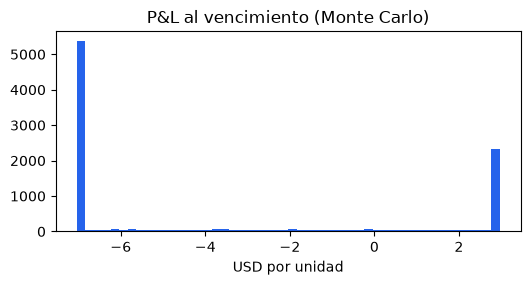

In [5]:
from quant.montecarlo import simular_precios
from quant.strategies_options import payoff_vencimiento
S0, sig, T = 100.0, 0.5, 30 / 365
ST = simular_precios(S0, sig, T, 10_000, mu=0.0, semilla=1)
legs = [{'type': 'call', 'strike': 100.0, 'side': 1, 'qty': 1, 'price': precio(S0, 100, T, 0.045, sig)},
        {'type': 'call', 'strike': 110.0, 'side': -1, 'qty': 1, 'price': precio(S0, 110, T, 0.045, sig)}]
costo = legs[0]['price'] - legs[1]['price']
pnl = payoff_vencimiento(legs, ST) - costo
print(f'Costo neto {costo:.2f} · prob. de ganancia {np.mean(pnl > 0):.1%} · valor esperado {pnl.mean():.3f} · P5 {np.percentile(pnl, 5):.2f} · P95 {np.percentile(pnl, 95):.2f}')
plt.figure(figsize=(6, 2.6)); plt.hist(pnl, bins=50, color='#2563eb'); plt.title('P&L al vencimiento (Monte Carlo)'); plt.xlabel('USD por unidad'); plt.show()

## 4. Random Forest del bot: hiperparámetros, métricas y Diebold-Mariano

Velas de 15 minutos de BTC/USDT (Binance mainnet, datos públicos). Objetivo: si el cierre sube dentro de 4 velas. Partición temporal 70/30 sin barajar, para no filtrar información del futuro.

In [6]:
from data_sources.market import velas
from bot.features import construir_features, etiqueta_objetivo, retorno_futuro
from validation.hyperparams import simular_grid, comparar_con_knn
from validation.diebold_mariano import diebold_mariano
df = velas('BTC/USDT', 'binance_spot_testnet', '15m', 1500)
X, y, ret = construir_features(df), etiqueta_objetivo(df, 4), retorno_futuro(df, 4)
ok = X.notna().all(axis=1) & y.notna()
X, y, ret = X[ok], y[ok].astype(int), ret[ok]
print(f'{len(df)} velas desde {df.index[0]} hasta {df.index[-1]} · {X.shape[1]} variables')
tabla_hp, mejor = simular_grid(X, y, ret)
tabla_hp.drop(columns=['matriz_confusion']).head(10).round(4)

1500 velas desde 2026-11-03 15:15:00+00:00 hasta 2026-11-19 06:00:00+00:00 · 20 variables


,n_estimators,max_depth,min_samples_leaf,accuracy,precision,recall,f1,rmse,mse,mae,mape,smape,variance_score
0,100,10,5,0.4786,0.4279,0.4257,0.4268,0.3295,0.1086,0.2737,338.6727,156.8095,-0.1612
1,50,6,10,0.5079,0.4551,0.4010,0.4263,0.3218,0.1035,0.2682,258.0205,158.4671,-0.1120
2,50,10,1,0.4786,0.4256,0.4109,0.4181,0.3337,0.1113,0.2767,380.9113,155.4308,-0.1938
3,50,10,5,0.4515,0.4047,0.4307,0.4173,0.3324,0.1105,0.2761,258.9878,157.4175,-0.1791
4,200,10,5,0.4763,0.4235,0.4109,0.4171,0.3272,0.1070,0.2713,336.9380,156.2574,-0.1463
5,100,6,10,0.4898,0.4341,0.3911,0.4115,0.3216,0.1035,0.2685,269.8681,158.4817,-0.1102
6,100,10,10,0.4898,0.4333,0.3861,0.4084,0.3259,0.1062,0.2712,396.9892,157.4916,-0.1393
7,200,10,1,0.4763,0.4211,0.3960,0.4082,0.3324,0.1105,0.2761,399.5452,155.4859,-0.1850
8,50,10,10,0.4650,0.4112,0.4010,0.4060,0.3285,0.1079,0.2728,307.5063,158.1262,-0.1571
9,200,6,10,0.4966,0.4393,0.3762,0.4053,0.3207,0.1028,0.2682,286.3518,159.2083,-0.1042


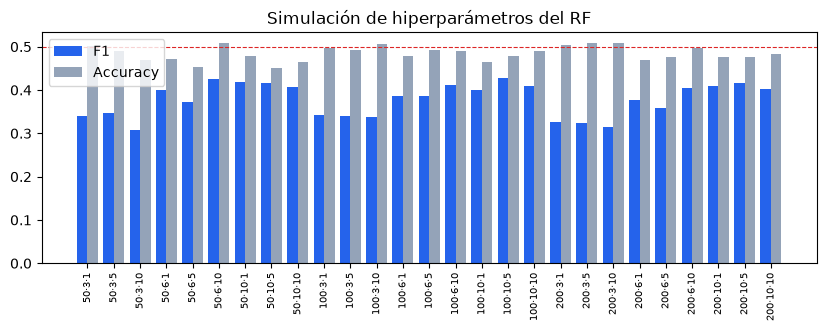

Mejor combinación: {'n_estimators': 100, 'max_depth': 10, 'min_samples_leaf': 5}


In [7]:
fig, ax = plt.subplots(figsize=(10, 3))
t = tabla_hp.sort_values(['n_estimators', 'max_depth', 'min_samples_leaf'])
etq = [f'{a}·{b}·{c}' for a, b, c in zip(t.n_estimators, t.max_depth, t.min_samples_leaf)]
ax.bar(np.arange(len(t)) - 0.2, t.f1, 0.4, label='F1', color='#2563eb'); ax.bar(np.arange(len(t)) + 0.2, t.accuracy, 0.4, label='Accuracy', color='#94a3b8')
ax.set_xticks(range(len(t)), etq, rotation=90, fontsize=7); ax.axhline(0.5, color='#dc2626', ls='--', lw=0.8); ax.legend(); ax.set_title('Simulación de hiperparámetros del RF'); plt.show()
print('Mejor combinación:', mejor['hyperparams'])

In [8]:
knn = comparar_con_knn(X, y, ret)
filas = [{'modelo': 'Random Forest', **{k: mejor[k] for k in ['accuracy', 'precision', 'recall', 'f1', 'rmse', 'mse', 'mae', 'mape', 'smape', 'variance_score']}},
         {'modelo': 'KNN (k=15)', **{k: knn[k] for k in ['accuracy', 'precision', 'recall', 'f1', 'rmse', 'mse', 'mae', 'mape', 'smape', 'variance_score']}}]
display(pd.DataFrame(filas).round(4))
print('Matriz de confusión RF [[TN, FP], [FN, TP]]:', mejor['matriz_confusion'])
dm = diebold_mariano(mejor['_error'], knn['error'], h=4)
pd.Series(dm.to_dict())

,modelo,accuracy,precision,recall,f1,rmse,mse,mae,mape,smape,variance_score
0,Random Forest,0.4786,0.4279,0.4257,0.4268,0.3295,0.1086,0.2737,338.6727,156.8095,-0.1612
1,KNN (k=15),0.5102,0.4400,0.2723,0.3364,0.3353,0.1124,0.2761,336.2947,146.3940,-0.1973


Matriz de confusión RF [[TN, FP], [FN, TP]]: [[126, 115], [116, 86]]


dm                 -0.546984
dm_hln             -0.542662
p_valor             0.587636
n                        443
horizonte                  4
mejor                 empate
diferencia_media   -0.003811
dtype: object

Interpretación de Diebold-Mariano: H0 es igual precisión predictiva. Un estadístico HLN negativo con p < 0.05 indica que el RF tiene menor pérdida cuadrática; con p ≥ 0.05 no hay evidencia para preferir un modelo sobre el otro.

## 5. Resultados registrados por el sistema en la VM

Tablas exportadas desde la base de datos de producción con `scripts/exportar_resultados.py`.

In [9]:
display(pd.read_csv(RES / 'diebold_mariano.csv').round(4))
display(pd.read_csv(RES / 'confusion_en_vivo.csv').round(4))
pd.read_csv(RES / 'desempeno_bot.csv').round(3)

,activo,comparacion,dm,dm_hln,p_valor,n,h,resultado
0,NVDA,RF vs KNN (base),0.7410,0.7351,0.4627,443,4,Sin diferencia significativa
1,NVDA,RF vs EMA50 + Chandelier,-4.1747,-4.1417,0.0000,443,4,RF mejor
2,NVDA,RF vs Reversión RSI,2.0408,2.0246,0.0435,443,4,Reversión RSI mejor
3,NVDA,RF vs Cruce MACD,1.4420,1.4306,0.1533,443,4,Sin diferencia significativa
4,SOL/USDT,RF vs KNN (base),0.3823,0.3793,0.7046,443,4,Sin diferencia significativa
5,SOL/USDT,RF vs EMA50 + Chandelier,-4.6371,-4.6005,0.0000,443,4,RF mejor
6,SOL/USDT,RF vs Reversión RSI,1.2507,1.2408,0.2153,443,4,Sin diferencia significativa
7,SOL/USDT,RF vs Cruce MACD,0.0772,0.0766,0.9390,443,4,Sin diferencia significativa
8,BTC/USDT,RF vs KNN (base),-1.1735,-1.1642,0.2450,443,4,Sin diferencia significativa
9,BTC/USDT,RF vs EMA50 + Chandelier,-6.9834,-6.9282,0.0000,443,4,RF mejor


,activo,senales_evaluadas,accuracy,precision,recall,f1,matriz_confusion
0,BTC/USDT,136,0.3676,0.303,0.3333,0.3175,"[[30, 46], [40, 20]]"
1,NVDA,30,0.5667,0.000,0.0000,0.0000,"[[17, 0], [13, 0]]"
2,SOL/USDT,137,0.4088,0.383,0.2571,0.3077,"[[38, 29], [52, 18]]"
3,SPY,23,0.3913,0.300,0.3000,0.3000,"[[6, 7], [7, 3]]"


,activo,estrategia,venue,operaciones,operaciones_validas,cantidad_cero,salida_en_vela_de_entrada,pnl_usd,roi_pct,sharpe_por_operacion,sortino_por_operacion,max_drawdown_pct,win_rate_pct
0,BTC/USDT,Cruce MACD,binance_spot_testnet,4,4,0,0,3.492,0.349,0.091,0.303,-1.178,25.000
1,BTC/USDT,EMA50 + Chandelier,binance_spot_testnet,5,5,0,1,-22.073,-2.207,-1.325,-1.325,-2.207,0.000
2,BTC/USDT,Random Forest,binance_spot_testnet,15,15,0,0,-4.155,-0.416,-0.044,-0.063,-2.403,40.000
3,BTC/USDT,Reversión RSI,binance_spot_testnet,1,1,0,0,-6.954,-0.695,0.000,0.000,-0.695,0.000
4,BTC/USDT,Votación,binance_spot_testnet,2,2,0,0,7.358,0.736,0.606,0.000,-0.061,50.000
5,NVDA,Cruce MACD,alpaca_paper,1,0,1,0,0.000,0.000,0.000,0.000,0.000,NaN
6,NVDA,EMA50 + Chandelier,alpaca_paper,3,0,3,1,0.000,0.000,0.000,0.000,0.000,NaN
7,NVDA,Random Forest,alpaca_paper,2,0,2,1,0.000,0.000,0.000,0.000,0.000,NaN
8,NVDA,Votación,alpaca_paper,2,0,2,1,0.000,0.000,0.000,0.000,0.000,NaN
9,SOL/USDT,Cruce MACD,binance_spot_testnet,3,3,0,1,22.863,2.286,0.326,1.050,-1.126,33.333


In [10]:
display(pd.read_csv(RES / 'correlacion_pearson.csv', index_col=0).round(3))
pd.read_csv(RES / 'markowitz_carteras.csv').round(4)

,BTC,SOL,NVDA,SPY,INTC
Ticker,,,,,
BTC,1.000,0.873,0.394,0.476,0.238
SOL,0.873,1.000,0.365,0.422,0.230
NVDA,0.394,0.365,1.000,0.629,0.425
SPY,0.476,0.422,0.629,1.000,0.522
INTC,0.238,0.230,0.425,0.522,1.000


,cartera,ret,vol,sharpe,w_BTC,w_SOL,w_NVDA,w_SPY,w_INTC
0,Máximo Sharpe,0.2459,0.2467,0.9965,0.0083,0.0128,0.0120,0.7721,0.1948
1,Mínima volatilidad,0.0587,0.1641,0.3579,0.0899,0.0531,0.0067,0.8493,0.0008
